<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Regression and Classification: Evaluating Classification Models
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>


---

### Summary

In this chapter we explore how classification models are evaluated and compared in real-world machine learning workflows. Through a combination of theory, hands-on exercises, and practical examples, we will examine how to train multiple classification models, validate their performance using cross-validation, and optimise them using hyperparameter tuning. We will focus particularly on evaluating models in imbalanced datasets using precision and recall, comparing models against baseline performance, and interpreting results in a policy or decision-making context.


### Learning Objectives

* Understand how classification models are trained and evaluated in a machine learning workflow
* Recognise the challenges posed by **imbalanced datasets** and why accuracy can be misleading
* Train multiple classification models including logistic regression, decision trees, and random forests
* Apply **train–test splitting** and understand the importance of evaluating models on unseen data
* Use **cross-validation** to estimate model performance and assess model stability
* Compare models using appropriate metrics such as **precision and recall**
* Perform **hyperparameter tuning using GridSearchCV** to optimise model performance
* Understand the purpose of **baseline models** and compare trained models against random prediction
* Interpret classification model performance using confusion matrices and evaluation metrics
* Connect model evaluation results to **practical decision-making contexts**



### Overview

[**Understanding the classification problem**](#classification_problem)

* What is the prediction task?
* Why is this a classification problem?
* What challenges arise when the dataset is imbalanced?
* *Challenge*: Explore the class distribution

[**Preparing data for model training**](#data_preparation)

* Why do we split data into training and test sets?
* What is stratified sampling?
* How does train–test splitting prevent data leakage?
* *Demo*: Use `train_test_split()` in `sklearn`

[**Training classification models**](#model_training)

* What are logistic regression, decision trees, and random forests?
* Why train multiple models?
* How do models learn patterns from training data?
* *Demo*: Train models using `sklearn` classifiers

[**Evaluating models with cross-validation**](#cross_validation)

* What is cross-validation?
* Why do we evaluate models across multiple folds?
* How do we interpret variation in model performance?
* *Challenge*: Compare cross-validation scores

[**Improving models with hyperparameter tuning**](#hyperparameter_tuning)

* What are hyperparameters?
* How does grid search help improve model performance?
* How does `GridSearchCV` work?
* *Demo*: Tune classification models using `GridSearchCV`

[**Comparing models objectively**](#model_comparison)

* How do we compare multiple trained models?
* Why visualise cross-validation scores?
* What does a boxplot of model performance tell us?
* *Challenge*: Compare model stability and performance

[**Using baseline models for context**](#baseline_models)

* What is a baseline model?
* Why compare models against random predictions?
* How do we implement a `DummyClassifier`?
* *Challenge*: Evaluate baseline performance

[**Evaluating the final model**](#final_model_evaluation)

* Why must the final model be evaluated on the test set?
* What are precision and recall?
* How do we interpret confusion matrix outcomes?
* *Challenge*: Interpret model predictions in context



### Introductions

#### Purpose: What is the aim of the content?

The purpose of this workshop is to develop a clear understanding of how classification models are evaluated and compared in practice. While training models is an important step in machine learning, selecting the most appropriate model requires careful evaluation using appropriate metrics and validation techniques. In this lesson, learners will explore how to compare multiple models, apply cross-validation, optimise models through hyperparameter tuning, and interpret performance metrics such as precision and recall. These skills are essential for building reliable models that support real-world decision-making.



#### Objectives: What will I learn?

* Understand the workflow for training and evaluating classification models
* Recognise the impact of class imbalance on model evaluation
* Train and compare multiple classification algorithms
* Apply cross-validation to estimate model performance
* Perform hyperparameter tuning using grid search
* Evaluate models using precision and recall metrics
* Implement baseline models for meaningful comparison
* Interpret classification outcomes using confusion matrices
* Connect model evaluation results to real-world decision contexts


#### Process: How will I learn this content?

Throughout the workshop, we will:

* explore concepts through short explanations and examples
* train and evaluate models using Python and `scikit-learn`
* compare model performance using visualisations and metrics
* complete guided exercises and challenges
* discuss how evaluation results inform real-world decisions



#### Applications: Why study this?

Classification models are widely used to support decision-making across many domains, including finance, healthcare, public policy, marketing, and social research. However, selecting a model based solely on accuracy can lead to misleading conclusions, particularly when datasets are imbalanced. Understanding how to properly evaluate classification models using metrics such as precision and recall allows analysts to assess the real impact of model predictions. These evaluation techniques help ensure that machine learning models provide meaningful insights and reliable support for policy, business, and operational decisions.






---
# Problem Statement
---





We are building a **classification model** to predict whether an individual or household is likely to experience **residential out-migration**. In this context, the target variable (Y) represents a binary outcome:

* **(Y = 1)** indicates that a person or household leaves the area (out-migration)
* **(Y = 0)** indicates that they remain in the area

The model uses a range of explanatory features to estimate the probability that an individual belongs to one of these two categories. These features may include demographic, economic, or housing-related characteristics that help explain patterns of residential mobility.

The purpose of this model is not simply to make predictions, but to **support policy decision-making**. In particular, the model is designed to help identify groups or areas where the risk of out-migration is higher. These insights can then be used to inform **targeted interventions under the Programme for Government**, such as initiatives aimed at retaining graduates, supporting housing stability, or strengthening regional economic opportunities.

Because policy resources are limited, the model must be evaluated carefully to ensure that interventions are directed toward individuals who are genuinely at risk of leaving. This is why metrics such as **precision and recall** become important. Precision helps ensure that resources are not wasted on individuals who would not have left anyway, while recall measures how effectively the model identifies those who are truly at risk.

In this lesson, we will explore how classification models can be trained, validated, and evaluated in order to support this type of evidence-based policy decision-making.

---

## Data dictionary

All feature columns are continuous, standardised numerical scores. A value near `0` represents the dataset average, positive values are above average, and negative values are below average.

| Column                                 | Role       |           Data type | Description                                                                                                                    | Higher values indicate                          |
| -------------------------------------- | ---------- | ------------------: | ------------------------------------------------------------------------------------------------------------------------------ | ----------------------------------------------- |
| `young_adult_profile_score`            | Feature    |               Float | Represents the extent to which the resident or household matches the characteristics associated with a young-adult population. | A stronger young-adult profile                  |
| `household_income_score`               | Feature    |               Float | Represents the relative income position of the household compared with others in the dataset.                                  | A higher relative household income              |
| `qualification_level_score`            | Feature    |               Float | Represents the resident’s or household’s relative level of educational qualifications.                                         | Higher qualification levels                     |
| `housing_affordability_pressure_score` | Feature    |               Float | Represents the level of financial pressure created by housing costs relative to the resident’s circumstances.                  | Greater housing affordability pressure          |
| `employment_stability_score`           | Feature    |               Float | Represents the stability and continuity of employment associated with the profile.                                             | More stable employment                          |
| `housing_tenure_instability_score`     | Feature    |               Float | Represents the extent to which the resident’s housing situation may be temporary, insecure or subject to change.               | Greater housing instability                     |
| `public_service_access_score`          | Feature    |               Float | Represents relative access to services such as healthcare, education, childcare and other public provision.                    | Better access to public services                |
| `transport_connectivity_score`         | Feature    |               Float | Represents how well connected the resident’s area is through public transport or wider transport infrastructure.               | Better transport connectivity                   |
| `limited_local_job_opportunity_score`  | Feature    |               Float | Represents the extent to which suitable employment opportunities are limited within the local area.                            | Fewer suitable local job opportunities          |
| `recent_graduate_profile_score`        | Feature    |               Float | Represents the extent to which the profile has characteristics associated with a recent graduate.                              | A stronger recent-graduate profile              |
| `household_dependency_score`           | Feature    |               Float | Represents the level of caring, family or financial dependencies associated with the household.                                | Greater household dependency                    |
| `community_attachment_score`           | Feature    |               Float | Represents the resident’s relative connection to their local community, including social, family or place-based ties.          | Stronger attachment to the local community      |
| `residential_out_migration`            | **Target** | Integer: `0` or `1` | Records whether the resident or household remained in the area or experienced residential out-migration.                       | `0` = remained in the area; `1` = left the area |



## Imports for the Notebook

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, cross_validate, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score,
    precision_recall_curve, auc
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


In [29]:
# Add this as the first line of the code cell:

from IPython.display import display, HTML; display(HTML("<style>.cell-input { display: none !important; }</style>"))

### Importing the Dataset

<details>
<summary><b>✏️ Practice: Read the data file</b></summary>
<br>

#### Read the data file - "residential_out_migration.csv"

```python
df = pd.read_csv("__________")
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
df = pd.read_csv('residential_out_migration_classification.csv')
```

</details>

<details>
<summary><b>✏️ Practice: Examine a few columns</b></summary>
<br>

#### Examine a few columns

```python
df.__________()
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
df.head()
```

</details>

<details>
<summary><b>✏️ Practice: Split data into feature and target</b></summary>
<br>

#### Split our data to feature and target

```python
y = df["__________"]
X = df.drop(columns=["__________"])
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
y = df["residential_out_migration"]
X = df.drop(columns=["residential_out_migration"])
```

</details>

##### Hints / Solution

In [ ]:

df = pd.read_csv('residential_out_migration_classification.csv')
y = df["residential_out_migration"]
X = df.drop(columns=["residential_out_migration"])

##  Looking at the Class Distribution


It appears that the dataset is imbalanced, so as mentioned earlier the - accuracy is not a good metric to evaluate the model performance. We will use precision as our primary metric to evaluate the model performance.

<details>
<summary><b>✏️ Practice: Plot class distribution</b></summary>
<br>

##### We use count plot to display the distribution here 
```python
y.__________().plot(kind="__________")
plt.title("__________")
plt.show()
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
y.value_counts().plot(kind='bar')
plt.title('Migration Distribution')
plt.show()
```

</details>

## Train/Test Split


Now we will split the data into a training set and a test set. The training set will be used to train the model, and the test set will be used to evaluate the model's performance on unseen data. Remember:

- stratify the split to maintain the class distribution in both sets. Since the dataset is imbalanced
- do not toouch the test set in any way until the final evaluation step. The test set should only be used once to evaluate the final model performance.

<details>
<summary><b>✏️ Practice: Train/Test Split</b></summary>
<br>

```python
X_train, X_test, y_train, y_test = train_test_split(
    __________,
    __________,
    test_size=__________,
    stratify=__________,
    random_state=__________
)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, stratify=y, random_state=42)
```

</details>

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

## Model Fitting


Let us first instantiate our classifcation models

<details>
<summary><b>✏️ Practice: Instantiate Classification Models</b></summary>
<br>

```python
# let's do guess here
# lr = logistic regression ; dt = decision tree ; rf = random forest

model_lr = __________()
model_dt = __________(random_state=__________)
model_rf = __________(random_state=__________)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
model_lr = LogisticRegression()
model_dt = DecisionTreeClassifier(random_state=42)
model_rf = RandomForestClassifier(random_state=42)
```

</details>

In [ ]:

model_lr = LogisticRegression()
model_dt = DecisionTreeClassifier(random_state=42)
model_rf = RandomForestClassifier(random_state=42)

we will fit our models

<details>
<summary><b>✏️ Practice: Fit Classification Models</b></summary>
<br>

```python
# How do we fit our model here?
model_lr.__________(__________, __________)
model_dt.__________(__________, __________)
model_rf.__________(__________, __________)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)
model_rf.fit(X_train, y_train)
```

</details>

In [ ]:


model_lr.fit(X_train, y_train)
model_dt.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In the next section we jump straight to cross validation as the single train/test split is not enough to evaluate the models. (remeber, our  model might get lucky with the train/test split so we do k-folds cross validation to get a better estimate of the model performance)


---
# Selecting Our Evaluation Metric For This Problem
---



## Policy Context

We are predicting **residential out-migration (Y=1)** to inform targeted interventions under the Programme for Government.

Public funds are limited. Every intervention must be defensible.

---
## Cost of Errors
---

### False Positive (FP)

We intervene, but the resident would have stayed anyway.

**Cost:**

* Deadweight loss (wasted subsidy)
* Reduced funds for genuine cases
* Audit and accountability risk

This is an **immediate, measurable fiscal cost**.

### False Negative (FN)

We fail to intervene, and the resident leaves.

**Cost:**

* Long-term economic and demographic impact
* Harder to measure directly in the short term

This is a **strategic, longer-term cost**.


---

## Why Precision Is Prioritised
---


Precision answers:

> “When we intervene, how often are we correct?”

High precision ensures:

* Interventions are tightly targeted
* Public money is not wasted
* Decisions withstand scrutiny

In a budget-constrained public sector environment, avoiding expenditure on ineffective interventions is crucial.

---
## Policy Trade-Off
---

We accept:

* Some at-risk residents may not be identified (lower recall)

In exchange for:

* High confidence that funded interventions are justified

This is a deliberate choice to prioritise **resource efficiency and accountability**.



## Cross-Validation


#### Unique feature of cross-validation in classification problem

* Unlike regression we have to consider class balance so we will use stratified k folds instead of the usual kfolds

<details>
<summary><b>💡 Copy and paste the cell here to a new code cell to set up our cross validation</b></summary>
<br>

```python

# Set up the Kfold cross validation
strat_kfolds = StratifiedKFold(
    n_splits=__________,
    shuffle=__________,
    random_state=__________
)
```

```python
# Cross-validation for Logistic Regression model
cv_scores_lr = cross_validate(
    __________,
    __________,
    __________,
    cv=__________,
    scoring=("__________", "__________")
)
```

</details>

<details>
<summary><b>🔍 Copy and paste the cell in a new cell to display the summary</b></summary>
<br>

```python
### Display the cross validation result as a dataframe 
cv_results_lr = pd.__________(__________)
### print the summary statistics here
print(cv_results_lr.__________())
```

</details>

<details>
<summary><b>🔍 Want some tips/hints here?</b></summary>
<br>

```python
# consider class imbalance and use stratified k-fold cross-validation
strat_kfolds = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
# Cross-validation for Logistic Regression model
cv_scores_lr = cross_validate(model_lr, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall" ))
# Present your cv scores in a dataframe
cv_results_lr = pd.DataFrame(cv_scores_lr)
# write your summary statistics
print(cv_results_lr.describe())
```

</details>

In [ ]:
# consider class imbalance and use stratified k-fold cross-validation
strat_kfolds = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
# Cross-validation for Logistic Regression model
cv_scores_lr = cross_validate(model_lr, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall" ))
# Present your cv scores in a dataframe
cv_results_lr = pd.DataFrame(cv_scores_lr)
# write your summary statistics
print(cv_results_lr.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.001937    0.001806        0.881649     0.204240
std    0.000281    0.000751        0.079479     0.036320
min    0.001542    0.001263        0.755556     0.150838
25%    0.001748    0.001366        0.860465     0.189944
50%    0.002048    0.001422        0.913043     0.205556
75%    0.002171    0.001904        0.914894     0.234637
max    0.002176    0.003074        0.964286     0.240223


<details>
<summary><b>💡 Practise with Decision Tree model</b></summary>
<br>

```python
# cross-validation for Decision Tree model
cv_scores_dt = cross_validate(
    __________,
    __________,
    __________,
    cv=__________,
    scoring=("__________", "__________")
)

# Convert to dataframe
cv_results_dt = pd.__________(__________)

# Print descriptive statistics
print(cv_results_dt.__________())
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution for Decision Tree CV</b></summary>
<br>

```python
cv_scores_dt = cross_validate(model_dt, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))
cv_results_dt = pd.DataFrame(cv_scores_dt)
print(cv_results_dt.describe())
```

</details>

In [ ]:

cv_scores_dt = cross_validate(model_dt, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))
cv_results_dt = pd.DataFrame(cv_scores_dt)
print(cv_results_dt.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.047702    0.001687        0.671229     0.689721
std    0.002772    0.000110        0.021333     0.022036
min    0.045052    0.001577        0.649485     0.659218
25%    0.046125    0.001646        0.651042     0.675978
50%    0.046488    0.001665        0.670157     0.698324
75%    0.048847    0.001673        0.690058     0.700000
max    0.051996    0.001872        0.695402     0.715084


<details>
<summary><b>💡 Practise with random forest model</b></summary>
<br>

```python
# cross-validation for Random Forest model
cv_scores_rf = cross_validate(
    __________,
    __________,
    __________,
    cv=__________,
    scoring=("__________", "__________")
)
cv_results_rf = pd.__________(__________)
print(cv_results_rf.__________())
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution for Random Forest CV</b></summary>
<br>

```python
cv_scores_rf = cross_validate(model_rf, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))
cv_results_rf = pd.DataFrame(cv_scores_rf)
print(cv_results_rf.describe())
```

</details>

In [36]:
cv_scores_rf = cross_validate(model_rf, X_train, y_train, cv=strat_kfolds, scoring=("precision","recall"))
cv_results_rf = pd.DataFrame(cv_scores_rf)
print(cv_results_rf.describe())

       fit_time  score_time  test_precision  test_recall
count  5.000000    5.000000        5.000000     5.000000
mean   0.738397    0.008314        0.959202     0.648430
std    0.064388    0.000485        0.016303     0.048121
min    0.689323    0.007776        0.939850     0.575419
25%    0.695780    0.007983        0.949580     0.631285
50%    0.716078    0.008172        0.960630     0.655556
75%    0.743626    0.008744        0.962617     0.681564
max    0.847178    0.008895        0.983333     0.698324


#### An alternative presentation of your precision scores across different models

* We can manually cross reference the precision scores across the different models,
* We can use boxplots to visualise the distribution of precision scores across the different models.

<details>
<summary><b>✏️ Practice: Combine CV Precision Results & Plot Boxplot</b></summary>
<br>

```python
# group your cross validation results into one single dataframe
cv_results = pd.concat(
    [
        cv_results_lr["__________"],
        cv_results_dt["__________"],
        cv_results_rf["__________"]
    ],
    axis=__________
)

# create a box plot
cv_results.__________()

plt.title("__________")
plt.ylabel("__________")
plt.xlabel("__________")
plt.xticks(
    [1, 2, 3],
    ["__________", "__________", "__________"]
)
plt.show()
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
cv_results = pd.concat([cv_results_lr["test_precision"], cv_results_dt["test_precision"], cv_results_rf["test_precision"]], axis=1)
cv_results.boxplot()

plt.title('Cross-Validation Precision Scores')
plt.ylabel('Precision')
plt.xlabel('Model')
plt.xticks([1, 2, 3], ['Logistic Regression', 'Decision Tree', 'Random Forest'])
plt.show()
```

</details>

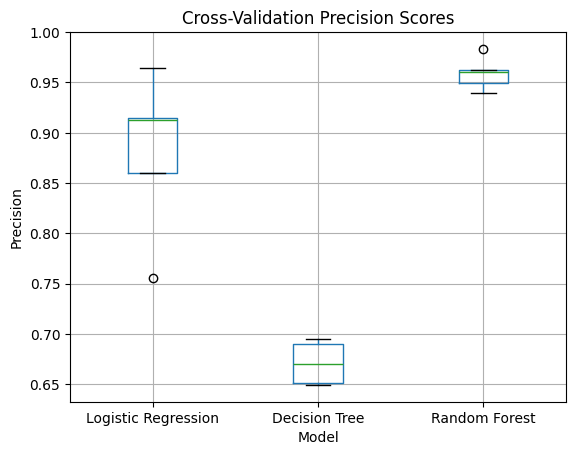

In [ ]:

cv_results = pd.concat([cv_results_lr["test_precision"], cv_results_dt["test_precision"], cv_results_rf["test_precision"]], axis=1)
cv_results.boxplot()
plt.title('Cross-Validation Precision Scores')
plt.ylabel('Precision')
plt.xlabel('Model')
plt.xticks([1, 2, 3], ['Logistic Regression', 'Decision Tree', 'Random Forest'])
plt.show()

Based on intital fits, the decision decision tree appears to have a much harder time being consistent in its precision scores. But remember, the intial fits are just that - initial. We will need to do hyperparameter tuning to see if we can improve the performance of our models

## Hyperparameter Tuning

* Now you have picked the best model
* Next step is to optimise the parameters of your chosen model
* This process is called hyperparameter tuning

<details>
<summary><b>✏️ Practice: Define Logistic Regression Parameter Grid & GridSearch</b></summary>
<br>

```python
# Define the parameter grid for Logistic Regression model
param_grid_lr = {
    "C": __________,
    "l1_ratio": __________,
    "solver": __________
}

grid_lr = GridSearchCV(
    __________(),
    __________,
    cv=__________,
    scoring="__________"
)
grid_lr.__________(__________, __________)
best_model_lr = grid_lr.__________
print("Best parameters:", grid_lr.__________)
print("Best PR AUC (Logistic Regression):", grid_lr.__________)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}
grid_lr = GridSearchCV(
    LogisticRegression(),
    param_grid_lr,
    cv=strat_kfolds,
    scoring="average_precision"
)
grid_lr.fit(X_train, y_train)
best_model_lr = grid_lr.best_estimator_
print('Best parameters:', grid_lr.best_params_)
print('Best PR AUC (Logistic Regression):', grid_lr.best_score_)
```

</details>

In [ ]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'l1_ratio': [0,  1.0],
    'solver': ['liblinear']
}
grid_lr = GridSearchCV(
    LogisticRegression(),
    param_grid_lr,
    cv=strat_kfolds,
    scoring="average_precision"
)
grid_lr.fit(X_train, y_train)
best_model_lr = grid_lr.best_estimator_
print('Best parameters:', grid_lr.best_params_)
print('Best PR AUC (Logistic Regression):', grid_lr.best_score_)

Best parameters: {'C': 0.01, 'l1_ratio': 0.0, 'solver': 'liblinear'}
Best PR AUC (Logistic Regression): 0.5146850534314105


* Additional resources on defining parameter grid can be found [here](https://codesignal.com/learn/courses/intro-to-model-optimization-in-machine-learning/lessons/hyperparameter-tuning-in-logistic-regressions)

<details>
<summary><b>✏️ Practice: Random Forest Parameter Grid & GridSearch</b></summary>
<br>

```python
# Next we show the parameter grid for Random Forest model
param_grid_rf = {
    "n_estimators": __________,       # number of trees in the forest
    "max_depth": __________,          # maximum depth of each tree (controls complexity)
    "min_samples_split": __________,  # minimum number of samples required to split a node
    "min_samples_leaf": __________    # minimum number of samples required in a leaf node
}

grid_rf = GridSearchCV(
    __________(random_state=__________),
    __________,
    cv=__________,
    scoring="__________"
)
grid_rf.__________(__________, __________)
best_model_rf = grid_rf.__________
print("Best parameters:", grid_rf.__________)
print("Best CV PR AUC (Random Forest):", grid_rf.__________)
std = grid_rf.cv_results_["__________"][grid_rf.__________]
print(std)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
param_grid_rf= {
    'n_estimators': [10],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=strat_kfolds,
    scoring="average_precision"
)
grid_rf.fit(X_train, y_train)
best_model_rf = grid_rf.best_estimator_
print('Best parameters:', grid_rf.best_params_)
print('Best CV PR AUC (Random Forest):', grid_rf.best_score_)
std = grid_rf.cv_results_["std_test_score"][grid_rf.best_index_]
print(std)
```

</details>

In [ ]:

param_grid_rf= {
    'n_estimators': [10],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=strat_kfolds,
    scoring="average_precision"
)
grid_rf.fit(X_train, y_train)
best_model_rf = grid_rf.best_estimator_
print('Best parameters:', grid_rf.best_params_)
print('Best CV PR AUC (Random Forest):', grid_rf.best_score_)
std = grid_rf.cv_results_["std_test_score"][grid_rf.best_index_]
print(std)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 10}
Best CV PR AUC (Random Forest): 0.817302183675752
0.022676688518868896


---
##  Model Evaluation For Classification
---

#### Motivation
* How do we know that are model has learned anything at all?
* A great way is to create a baseline model model that just makes random prediction and see how our model performs against that baseline.

<details>
<summary><b>✏️ Practice: Baseline Dummy Classifier Evaluation</b></summary>
<br>

```python
# We use the dummy classifier as a baseline model to compare the performance of our other models.
dummy = DummyClassifier(
    strategy="__________",
    random_state=__________
)
dummy.__________(__________, __________)
y_dummy_pred = dummy.__________(__________)

print("Dummy Accuracy:", __________(__________, __________))
print("Dummy Precision:", __________(__________, __________, zero_division=__________))
print("Dummy Recall:", __________(__________, __________, zero_division=__________))

# Present the confusion matrix
fig, axes = plt.subplots(__________, __________, figsize=__________)

ConfusionMatrixDisplay.from_predictions(
    __________,
    __________,
    ax=axes[__________],
    values_format="__________"
)
axes[__________].set_title("__________")

# Normalised
ConfusionMatrixDisplay.from_predictions(
    __________,
    __________,
    normalize="__________",
    ax=axes[__________],
    values_format="__________"
)
axes[__________].set_title("__________")
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train, y_train)
y_dummy_pred = dummy.predict(X_test)

print("Dummy Accuracy:", accuracy_score(y_test, y_dummy_pred))
print("Dummy Precision:", precision_score(y_test, y_dummy_pred, zero_division=0))
print("Dummy Recall:", recall_score(y_test, y_dummy_pred, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_dummy_pred, ax=axes[0], values_format="d")
axes[0].set_title("Confusion Matrix (Counts)")

ConfusionMatrixDisplay.from_predictions(y_test, y_dummy_pred, normalize="true", ax=axes[1], values_format=".2f")
axes[1].set_title("Confusion Matrix (Normalised)")
```

</details>

In [40]:
dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train, y_train)
y_dummy_pred = dummy.predict(X_test)
print("Dummy Accuracy:", accuracy_score(y_test, y_dummy_pred))
print("Dummy Precision:", precision_score(y_test, y_dummy_pred, zero_division=0))
print("Dummy Recall:", recall_score(y_test, y_dummy_pred, zero_division=0))


Dummy Accuracy: 0.7325
Dummy Precision: 0.16580310880829016
Dummy Recall: 0.16666666666666666


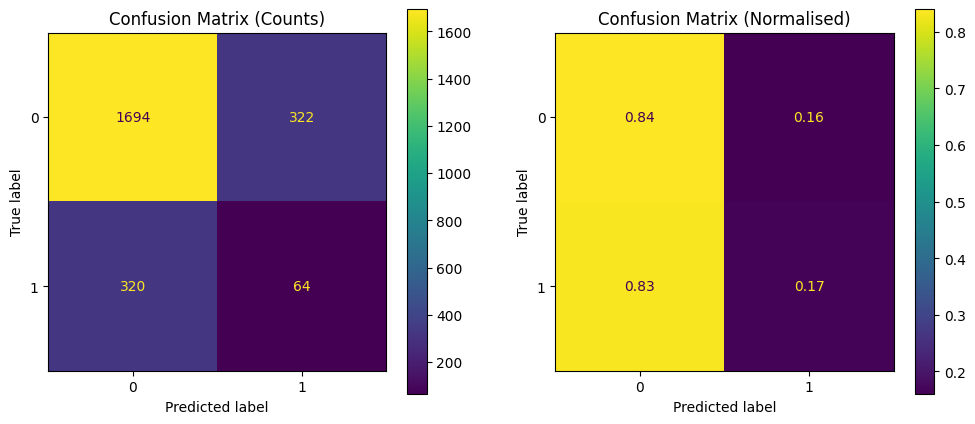

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_dummy_pred, ax=axes[0], values_format="d")
axes[0].set_title("Confusion Matrix (Counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_dummy_pred, normalize="true", ax=axes[1], values_format=".2f")
axes[1].set_title("Confusion Matrix (Normalised)")

plt.show()

# Policy Interpretation

Random guessing results show that:

when the model predicts a resident will leave, it is correct only about 17% of the time (precision ~17%).

Only ~17% of true leavers would be identified.

Most funding would be misdirected.

This is not a viable policy tool.

---
# Evaluating The Best Model
---

we import the best model from the previous section

<details>
<summary><b>✏️ Practice: Evaluate Best Model on Test Set</b></summary>
<br>

```python
best_model = __________
y_pred = best_model.__________(__________)

fig, axes = plt.subplots(
    __________,
    __________,
    figsize=__________
)

# Raw counts
ConfusionMatrixDisplay.from_predictions(
    __________,
    __________,
    ax=axes[__________],
    values_format="__________"
)
axes[__________].set_title("__________")

# Normalised
ConfusionMatrixDisplay.from_predictions(
    __________,
    __________,
    normalize="__________",
    ax=axes[__________],
    values_format="__________"
)
axes[__________].set_title("__________")

plt.tight_layout()
plt.show()

print("Precision:", __________(__________, __________))
print("Recall:", __________(__________, __________))
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
best_model = best_model_rf
y_pred = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], values_format="d")
axes[0].set_title("Confusion Matrix (Counts)")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", ax=axes[1], values_format=".2f")
axes[1].set_title("Confusion Matrix (Normalised)")
plt.tight_layout()
plt.show()

print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
```

</details>

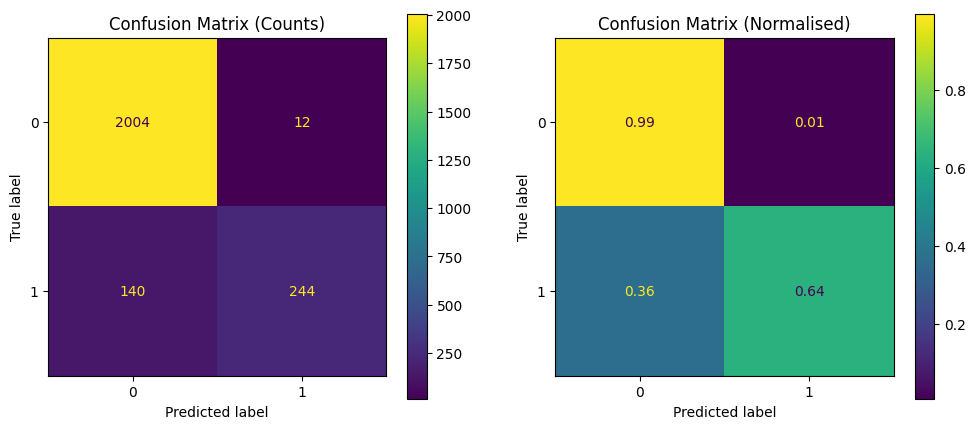

Precision: 0.953125
Recall: 0.6354166666666666


In [ ]:

best_model = best_model_rf
y_pred = best_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], values_format="d")
axes[0].set_title("Confusion Matrix (Counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", ax=axes[1], values_format=".2f")
axes[1].set_title("Confusion Matrix (Normalised)")

plt.show()
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))

#### Discuss

* Compare the performance of random forest model versus the baseline
* What does it tell us?


## Precision

* When the model predicts that someone is at risk of leaving, it is correct about 96% of the time.

* So the misallocation of financial resources is very low.

#### Policy framing

* The model results in very little wasted intervention spending.

## Recall

* The model correctly identifies about 63% of the individuals who actually leave.

#### policy framing

* The model captures most at-risk individuals but does not detect all of them.
* The remaining 37% missed may still leave without intervention.

#### Trade-off

* The model prioritises accuracy of intervention over identifying every possible leaver.
* The model is very good at targeting interventions to those who are truly at risk, but it does not capture every single case.
* This is a common and acceptable trade-off in many real-world applications, especially when resources are limited and the cost of false positives is high.


## Train a classification model with low-code approach

Now that you are comfortable with what classification models are. Similar to regression, we can also use `pycaret` to help us build a classification model quickly


### The Game Plan

Here is how we are going to tackle this notebook:

* **Step 1:** Feed our dataset to PyCaret and let it handle the background setup.
* **Step 2:** Tell PyCaret to compare every major classification model available to find our top performer.
* **Step 3:** Crown the winning model and use it to make real-world predictions.

Scroll down, hit the first code block, and let's get started.

<details>
<summary><b>✏️ Practice: PyCaret Low-Code Classification</b></summary>
<br>

```python
# create a new dataframe for storing the data to be trained by pycaret
df_py = df.__________()

# import the pycaret library to build the object
from pycaret.classification import __________

# Store the training model
exp = ClassificationExperiment(
    target="__________",
    session_id=__________,
    fold=__________,
    n_jobs=__________,
    train_size=__________
).fit(__________)

result = exp.__________()
result.__________

best_model = result.__________
best_model
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
df_py = df.copy()
from pycaret.classification import ClassificationExperiment

exp = ClassificationExperiment(
    target="residential_out_migration",
    session_id=123,
    fold=5,
    n_jobs=1,
    train_size=0.8
).fit(df_py)

result = exp.compare_models()
result.leaderboard

best_model = result.best
best_model
```

</details>

In [43]:
df_py = df.copy()
from pycaret.classification import ClassificationExperiment
exp = ClassificationExperiment(target="residential_out_migration", session_id=123, fold=5, n_jobs=1, train_size=0.8).fit(df_py)
result = exp.compare_models()
result.leaderboard
best_model = result.best
best_model

,steps,"[('preprocess', ...), ('catboost', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numerical_pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


#### Which one is our best model?

Ask yourself:

- Which model performed best?
- Which metric is PyCaret sorting by?
- Is that the right metric for this problem?
- What would the business consequence of a false positive or false negative be?

---
## Optional stretch:

### further consideration: Adding uncertainty estimates to our predictions
---

As we mentioned in the Regression notebook, using a single value (point estimate) to evaluate model performance can be misleading. we use bootstrapping to measure the uncertainty in precision scores to get a better understanding of the model performance in the case the test set is slightly different than the one we have.

<details>
<summary><b>✏️ Practice: Bootstrap Uncertainty Estimates</b></summary>
<br>

```python
rng = np.random.default_rng(__________)

n_boot = __________
n = __________

boot_precisions = np.empty(__________)

# convert to numpy arrays to allow fancy indexing reliably
y_true = np.asarray(__________)
y_hat = np.asarray(__________)

for b in range(__________):
    idx = rng.integers(
        __________,
        __________,
        size=__________
    )  # sample indices with replacement

    boot_precisions[b] = precision_score(
        y_true[__________],
        y_hat[__________],
        zero_division=__________
    )

ci_low, ci_high = np.percentile(
    __________,
    __________
)

print(
    f"Precision (bootstrap 95% CI): "
    f"[{ci_low:.4f}, {ci_high:.4f}]"
)
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
rng = np.random.default_rng(42)

n_boot = 5000
n = len(y_test)

boot_precisions = np.empty(n_boot)

y_true = np.asarray(y_test)
y_hat = np.asarray(y_pred)

for b in range(n_boot):
    idx = rng.integers(0, n, size=n)
    boot_precisions[b] = precision_score(y_true[idx], y_hat[idx], zero_division=0)

ci_low, ci_high = np.percentile(boot_precisions, [2.5, 97.5])

print(f"Precision (bootstrap 95% CI): [{ci_low:.4f}, {ci_high:.4f}]")
```

</details>

In [ ]:


rng = np.random.default_rng(42)
n_boot = 5000
n = len(y_test)
boot_precisions = np.empty(n_boot)
y_true = np.asarray(y_test)
y_hat = np.asarray(y_pred)
for b in range(n_boot):
    idx = rng.integers(0, n, size=n)
    boot_precisions[b] = precision_score(y_true[idx], y_hat[idx], zero_division=0)
ci_low, ci_high = np.percentile(boot_precisions, [2.5, 97.5])
print(f"Precision (bootstrap 95% CI): [{ci_low:.4f}, {ci_high:.4f}]")

Precision (bootstrap 95% CI): [0.9256, 0.9770]


In simple terms, this means:

If we tested the model on another similar dataset, the precision might change a little.
The confidence interval shows how much it could realistically change.

So instead of saying:
The model is correct exactly 96% of the time,

Our test set is just one sample of data.

If you collected another similar dataset:
- Precision might be 93%
- or 96%
- or 98%

The interval shows the likely range.

we say:
It is probably between 93% and 98% correct, depending on the sample we happened to test it on.



---
### Optional stretch: further considerations - thresholding
---

At a threshold of 0.5 default threshold. the model achieves precision of 0.96, meaning only 4% of funded interventions would be misallocated. This reflects strong fiscal discipline. Lets us look at at an example of how we can improve of test accuracy by tuning the threshold

#### Compute precision recall curve function

* We then use the precision_recall_curve function to compute the precision-recall pairs for different probability thresholds.
* This function returns three arrays: precisions, recalls, and thresholds.
* The precisions and recalls arrays contain the precision and recall values for each threshold, while the thresholds array contains the corresponding probability thresholds.


<details>
<summary><b>✏️ Practice: Threshold Tuning & Decision Boundary Analysis</b></summary>
<br>

```python_practice
from sklearn.model_selection import cross_val_predict

y_probas_forest = cross_val_predict(
    __________,
    __________,
    __________,
    cv=__________,
    method="__________"
)
y_scores_forest = y_probas_forest[:, __________]

precisions, recalls, thresholds = precision_recall_curve(
    __________,
    __________
)

plt.plot(thresholds, precisions[:-1], label="__________")
plt.plot(thresholds, recalls[:-1], label="__________")
plt.xlabel("__________")
plt.ylabel("__________")
plt.legend()
plt.show()

target_precision = __________
valid = __________ >= __________
best_idx = np.argmax(__________[__________])

chosen_threshold = __________[__________][__________]
chosen_precision = __________[__________][__________]
chosen_recall = __________[__________][__________]

print("Chosen threshold:", __________)
print("Precision at threshold:", __________)
print("Recall at threshold:", __________)

y_train_pred_custom = (__________ >= __________).astype(__________)
y_test_scores = __________.predict_proba(__________)[:, __________]
y_test_pred_custom = (__________ >= __________).astype(__________)

print("Test precision:", __________(__________, __________))
print("Test recall:", __________(__________, __________))
```

</details>

<details>
<summary><b>💡 Click to Reveal Solution</b></summary>
<br>

```python
from sklearn.model_selection import cross_val_predict

y_probas_forest = cross_val_predict(best_model, X_train, y_train, cv=strat_kfolds, method="predict_proba")
y_scores_forest = y_probas_forest[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, y_scores_forest)

plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.legend()
plt.show()

target_precision = 0.975
valid = precisions[:-1] >= target_precision
best_idx = np.argmax(recalls[:-1][valid])

chosen_threshold = thresholds[valid][best_idx]
chosen_precision = precisions[:-1][valid][best_idx]
chosen_recall = recalls[:-1][valid][best_idx]

print("Chosen threshold:", chosen_threshold)
print("Precision at threshold:", chosen_precision)
print("Recall at threshold:", chosen_recall)

y_train_pred_custom = (y_scores_forest >= chosen_threshold).astype(int)
y_test_scores = best_model.predict_proba(X_test)[:, 1]
y_test_pred_custom = (y_test_scores >= chosen_threshold).astype(int)

print("Test precision:", precision_score(y_test, y_test_pred_custom))
print("Test recall:", recall_score(y_test, y_test_pred_custom))
```

</details>

In [ ]:


# Evaluate the best model using cross-validation
from sklearn.model_selection import cross_val_predict
# Get predicted probabilities for the positive class
y_probas_forest = cross_val_predict(best_model, X_train, y_train, cv=strat_kfolds, method="predict_proba")
# Get the predicted probabilities for the positive class (class 1)
y_scores_forest = y_probas_forest[:, 1]
# Compute precision-recall curve
precisions, recalls, thresholds = precision_recall_curve(y_train, y_scores_forest)


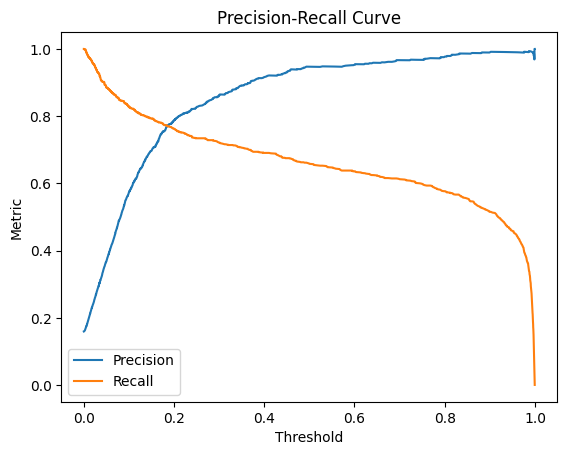

In [ ]:

# Plot precision and recall as a function of the decision threshold
plt.plot(thresholds, precisions[:-1], label="Precision")
# Plot recall as a function of the decision threshold
plt.plot(thresholds, recalls[:-1], label="Recall")
# Add labels and legend
plt.xlabel("Threshold")
# Add labels and legend
plt.ylabel("Metric")
# Add title
plt.title("Precision-Recall Curve")
plt.legend()
# display the plot
plt.show()


In [47]:
# Find the threshold that gives a precision of at least 0.975
target_precision = 0.975
# Find all thresholds that give a precision of at least 0.975
valid = precisions[:-1] >= target_precision
# Find the threshold that gives the highest recall among those that meet the precision requirement
best_idx = np.argmax(recalls[:-1][valid])


In [48]:
# Get the chosen threshold, precision, and recall
chosen_threshold = thresholds[valid][best_idx]
# Get the chosen precision and recall corresponding to the chosen threshold
chosen_precision = precisions[:-1][valid][best_idx]
#   Get the chosen recall corresponding to the chosen threshold
chosen_recall = recalls[:-1][valid][best_idx]


In [49]:
# Print the chosen threshold, precision, and recall
print("Chosen threshold:", chosen_threshold)
# Print the chosen precision and recall corresponding to the chosen threshold
print("Precision at threshold:", chosen_precision)
# Print the chosen recall corresponding to the chosen threshold
print("Recall at threshold:", chosen_recall)


Chosen threshold: 0.7917847339218259
Precision at threshold: 0.975609756097561
Recall at threshold: 0.5803571428571429


In [50]:
# Use the chosen threshold to make predictions on the training and test sets
y_train_pred_custom = (y_scores_forest >= chosen_threshold).astype(int)
# Make predictions on the test set using the chosen threshold
y_test_scores = best_model.predict_proba(X_test)[:, 1]
# Make predictions on the test set using the chosen threshold
y_test_pred_custom = (y_test_scores >= chosen_threshold).astype(int)
#  print the precision and recall for the test set using the custom threshold
print("Test precision:", precision_score(y_test, y_test_pred_custom))
print("Test recall:", recall_score(y_test, y_test_pred_custom))

Test precision: 0.9961685823754789
Test recall: 0.6770833333333334


### Additional resources

* A ultimate guide to hyperparameter tuning | grid search vs. randomised search
[https://www.youtube.com/watch?v=DTcfH5W6o08] (8 minutes)
* Machine learning: Hyperparameter tuning (GridsearchCV)
[https://www.youtube.com/watch?v=HdlDYng8g9s&t=284s] (11 minutes)
* [MLU explain: Logistic regression](https://mlu-explain.github.io/logistic-regression/)
* [StatQuest video on Logistic Regression (up to 5:15)](https://www.youtube.com/watch?v=yIYKR4sgzI8) (5min watch)
* [4 Logistic Regressions Examples to Help You Understand](https://magoosh.com/data-science/4-logistic-regressions-examples/) (2min read)
* [StatQuest video on Logistic Regression (from 6:10 to 8:08)](https://www.youtube.com/watch?v=yIYKR4sgzI8) (2 min)